# Dataset-size comparison: original 146 vs expanded 350 targets

Nine runs of the rank model (`configs/gate_rank.toml`): three arms $\times$ three seeds (7, 17, 27), 20 epochs each
(design: `DATASET_SIZE_COMPARISON.md`). All arms use stratified fold 1 of `expanded_target_splits` and share the
same 35 validation and 61 test targets (24 original, 37 from target-expansion batch 1); they differ only in training:

| arm | training targets | model |
|---|---|---|
| original only | 102 (the original targets of the fold's train split) | rank model |
| expanded | 254 (102 original + 152 batch 1, incl. the 45 training-only targets) | rank model |
| expanded, wide | same 254 | rank model widened to hidden 128 / latent 64 (0.97 M vs 0.26 M parameters) |

**Two checkpoints per run.** After epoch 10 every run evaluated its best-so-far checkpoint (lowest validation
DockQ MSE) on validation and test into `epoch10/` and kept training to epoch 20, untouched by the snapshot. The
final evaluation uses the same rule over all 20 epochs. The main comparison uses one stage for all runs: epoch 10
while any run is unfinished, final once all nine are done (stated below).

**Homolog leakage, by design.** The 45 training-only targets share one 30\%-identity chain cluster with an original
target and are in the expanded training set by design. In this fold 8 original test targets have such a homolog
(the trypsin-like protease group and 4k12); the original-only arm never sees those homologs. Test results are
therefore reported for three groups: *original, homolog in train* (8), *original, no homolog* (16) and *new* (37).

Figures use LaTeX Computer Modern, large labels, full borders and no titles. Spreads are SD over seeds; paired
intervals are bootstraps over targets.

In [1]:
from pathlib import Path
import json
import re
import shutil
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown

if shutil.which('latex') is None:
    raise RuntimeError('LaTeX is required to render the figures in Computer Modern.')
GATE = Path.cwd() if (Path.cwd() / 'dataset_size_comparison').is_dir() else Path.cwd() / 'gate_run'
ROOT = GATE / 'dataset_size_comparison'
EXPORT = GATE / 'dataset_size_comparison_analysis'; EXPORT.mkdir(exist_ok=True)
BATCH = Path('/scratch/ppi_target_expansion/targets_batch1.csv')
EPOCHS, SNAPSHOT, SEEDS = 20, 10, [7, 17, 27]
ARMS = ['original_only', 'expanded', 'expanded_large']
LABEL = {'original_only': 'Original only', 'expanded': 'Expanded', 'expanded_large': 'Expanded, wide'}
COLOR = {'original_only': '#000000', 'expanded': '#D55E00', 'expanded_large': '#0072B2'}
GRAY = {'original_only': '0.85', 'expanded': '0.45', 'expanded_large': '0.15'}
GROUPS = ['orig_homolog', 'orig_clean', 'new']
GROUP_LABEL = {'all': 'All 61', 'orig_homolog': 'Original,\nhomolog in train', 'orig_clean': 'Original,\nno homolog',
               'new': 'New (batch 1)'}
CAPRI = (0.23, 0.49, 0.80)

mpl.rcParams.update({'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'],
    'mathtext.fontset': 'cm', 'axes.labelsize': 23, 'xtick.labelsize': 17, 'ytick.labelsize': 17,
    'legend.fontsize': 17, 'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 1.1})

def save(fig, name):
    fig.savefig(EXPORT / (name + '.pdf'), bbox_inches='tight')
    fig.savefig(EXPORT / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()

# test-target groups
manifest = json.loads((ROOT / 'target_splits_expanded.json').read_text())
train_expanded = set(manifest['splits']['train']['targets'])
batch = pd.read_csv(BATCH)
homolog_of = {}
for r in batch[batch.training_only].itertuples():
    if r.pdb in train_expanded:
        for p in str(r.shares_one_chain_with).split(','):
            homolog_of.setdefault(p, set()).add(r.pdb)
new_targets = set(batch.pdb)
def group_of(t):
    return 'new' if t in new_targets else ('orig_homolog' if t in homolog_of else 'orig_clean')

## Data and checks

For each run and stage: the history never touched the test split; the evaluated checkpoint is the one with the
lowest validation DockQ MSE up to that stage; the validation predictions reproduce that MSE; the test predictions
reproduce the reported test MSE. All runs must share identical validation and test decoys and labels.

In [2]:
def run_dir(arm, seed):
    return ROOT / arm / f'gate_rank_seed{seed}'

steps, history, preds, reports, stage_done = [], [], {}, {}, {}
for arm in ARMS:
    for seed in SEEDS:
        d = run_dir(arm, seed)
        s = pd.read_csv(d / 'validation_steps.csv').assign(arm=arm, seed=seed)
        h = pd.read_csv(d / 'loss_history.csv').assign(arm=arm, seed=seed)
        if not h.filter(regex='^test_').isna().all().all():
            raise ValueError(f'{arm}/{seed}: test split evaluated during training')
        spe = s[(s.end_of_epoch == 1) & (s.epoch == 1)].global_step.iloc[0]
        s['epoch_float'] = s.global_step / spe
        steps.append(s); history.append(h)
        for stage, sd, last in (('epoch10', d / 'epoch10', SNAPSHOT), ('final', d, EPOCHS)):
            if not (sd / 'test_predictions.csv').exists():
                continue
            if stage == 'final' and h.epoch.max() != EPOCHS:
                raise ValueError(f'{arm}/{seed}: final predictions but only {h.epoch.max()} epochs')
            best = s[s.epoch <= last].val_target_mse.min()
            rep = json.loads((sd / 'prediction_metrics.json').read_text())
            v = pd.read_csv(sd / 'validation_predictions.csv'); t = pd.read_csv(sd / 'test_predictions.csv')
            if not np.isclose(rep['selected_checkpoint']['validation_target_mse'], best, rtol=1e-5):
                raise ValueError(f'{arm}/{seed}/{stage}: evaluated checkpoint is not the best validation checkpoint')
            if not np.isclose(np.mean((v.predicted_target - v.true_target) ** 2), best, rtol=1e-5, atol=1e-7):
                raise ValueError(f'{arm}/{seed}/{stage}: validation predictions do not reproduce the best validation MSE')
            if not np.isclose(np.mean((t.predicted_target - t.true_target) ** 2), rep['test']['pooled_mse'], rtol=1e-6):
                raise ValueError(f'{arm}/{seed}/{stage}: test predictions and metrics disagree')
            preds[arm, seed, stage] = dict(validation=v, test=t); reports[arm, seed, stage] = rep
        stage_done[arm, seed] = h.epoch.max()
steps = pd.concat(steps, ignore_index=True); history = pd.concat(history, ignore_index=True)

ref = {split: preds['original_only', 7, 'epoch10'][split][['target_id', 'graph_name', 'true_target']] for split in ('validation', 'test')}
for key, p in preds.items():
    for split in ('validation', 'test'):
        q = p[split]
        if not (q.graph_name.equals(ref[split].graph_name) and q.target_id.equals(ref[split].target_id)
                and np.allclose(q.true_target, ref[split].true_target)):
            raise ValueError(f'{key}: {split} cohort or labels differ')
if set(ref['validation'].target_id) & set(ref['test'].target_id):
    raise ValueError('validation and test targets overlap')
test_groups = ref['test'].drop_duplicates('target_id').set_index('target_id').index.map(group_of)
group_counts = pd.Series(test_groups).value_counts()

def stage_for(arms):
    """'final' if every run of these arms has finished, else the matched epoch-10 snapshot."""
    return 'final' if all((a, s, 'final') in preds for a in arms for s in SEEDS) else 'epoch10'
MAIN = stage_for(ARMS)
status = pd.DataFrame([dict(arm=a, seed=s, epochs_done=stage_done[a, s], epoch10=(a, s, 'epoch10') in preds,
                            final=(a, s, 'final') in preds) for a in ARMS for s in SEEDS])
display(status.pivot(index='arm', columns='seed', values='epochs_done').loc[ARMS])
print(f'{len(preds)} evaluated checkpoints passed all checks.')
print(f"Validation: {len(ref['validation']):,} decoys / {ref['validation'].target_id.nunique()} targets; "
      f"test: {len(ref['test']):,} decoys / {ref['test'].target_id.nunique()} targets; disjoint.")
print('Test groups:', ', '.join(f'{g} {group_counts.get(g, 0)}' for g in GROUPS))
print('Original test targets with a training-only homolog in the expanded train set:',
      ', '.join(f"{t} ({'/'.join(sorted(homolog_of[t]))})" for t in sorted(set(ref['test'].target_id) & set(homolog_of))))
display(Markdown(f"**Main comparison stage: `{MAIN}`** "
                 + ('(all nine runs finished).' if MAIN == 'final' else
                    '(some runs are still training; every run is compared at its epoch-10 snapshot).')))

seed,7,17,27
arm,,,
original_only,20,20,20
expanded,20,20,20
expanded_large,16,16,19


15 evaluated checkpoints passed all checks.
Validation: 52,043 decoys / 35 targets; test: 99,474 decoys / 61 targets; disjoint.
Test groups: orig_homolog 8, orig_clean 16, new 37
Original test targets with a training-only homolog in the expanded train set: 1acb (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 1avx (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 1cgi (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 1d6r (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 1oph (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 1ppe (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 2uuy (1brb/1brc/1k9o/3m7q/5c67/6gfi/7jr2/7qe9), 4k12 (4ayi/6zh1)


**Main comparison stage: `epoch10`** (some runs are still training; every run is compared at its epoch-10 snapshot).

## Training progress and time

Minutes per epoch from the training logs (array task 1/2/3 = seed 7/17/27), and the expected remaining time for
unfinished runs at their own mean pace.

In [3]:
rows = []
for arm in ARMS:
    for log in sorted((ROOT / arm / 'logs').glob('train_*.out')):
        task = int(re.search(r'_(\d+)\.out$', log.name).group(1)); seed = SEEDS[task - 1]
        mins = [float(m) for m in re.findall(r'^Epoch \d+ .*\(([\d.]+) min\)$', log.read_text(), flags=re.M)]
        snap = re.findall(r'^Snapshot after epoch \d+: .* \(([\d.]+) min\)$', log.read_text(), flags=re.M)
        done = len(mins)
        rows.append(dict(arm=arm, seed=seed, epochs_done=done, min_per_epoch=np.mean(mins) if mins else np.nan,
                         hours_so_far=sum(mins) / 60, snapshot_min=float(snap[0]) if snap else np.nan,
                         hours_left=(EPOCHS - done) * np.mean(mins) / 60 if mins else np.nan))
timing = pd.DataFrame(rows)
timing.to_csv(EXPORT / 'timing.csv', index=False)
display(timing.groupby('arm')[['epochs_done', 'min_per_epoch', 'hours_so_far', 'snapshot_min', 'hours_left']]
        .agg(['min', 'max']).loc[ARMS].round(1))

epochs_done     min_per_epoch        hours_so_far        \
                       min max           min    max          min   max   
arm                                                                      
original_only           20  20         131.0  149.3         43.7  49.8   
expanded                20  20         198.7  212.4         66.2  70.8   
expanded_large          16  19         222.6  263.3         68.5  70.5   

               snapshot_min      hours_left        
                        min  max        min   max  
arm                                                
original_only           3.9  6.7        0.0   0.0  
expanded                4.2  5.0        0.0   0.0  
expanded_large          4.7  6.1        3.7  17.6

## Learning curves

Left: validation DockQ MSE at every validation (thin: seeds; thick: seed mean; dots: new best checkpoint). Middle:
training DockQ MSE per epoch. Right: validation total loss per epoch (DockQ + reconstruction + ranking terms). The
dashed line marks the epoch-10 snapshot. Is the loss still going down after epoch 10?

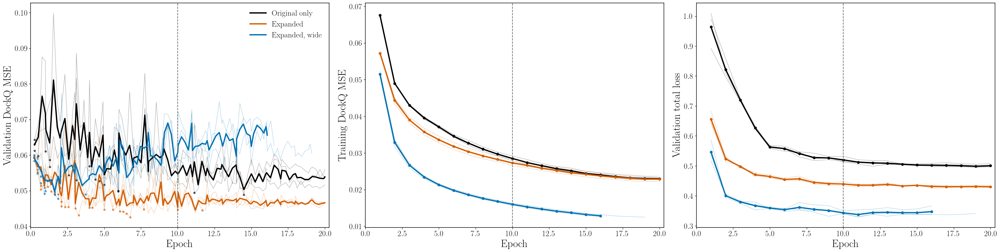

epochs_done  best_val_by_10  best_val_after_10  \
arm            seed                                                   
original_only  7              20          0.0517             0.0489   
               17             20          0.0500             0.0494   
               27             20          0.0498             0.0515   
expanded       7              20          0.0446             0.0445   
               17             20          0.0426             0.0448   
               27             20          0.0431             0.0437   
expanded_large 7              16          0.0499             0.0604   
               17             16          0.0477             0.0570   
               27             19          0.0478             0.0524   

                     best_epoch  val_loss_10  val_loss_last  train_mse_10  \
arm            seed                                                         
original_only  7             15       0.5317         0.5072        0.0279   
               17            12       0.5125         0.4966        0.0292   
               27             6       0.5152         0.4978        0.0284   
expanded       7             12       0.4375         0.4333        0.0265   
               17             7       0.4479         0.4303        0.0271   
               27             4       0.4329         0.4268        0.0283   
expanded_large 7              1       0.3497         0.3661        0.0157   
               17             2       0.3401         0.3367        0.0159   
               27             5       0.3396         0.3408        0.0163   

                     train_mse_last  improved_after_10  
arm            seed                                     
original_only  7             0.0228               True  
               17            0.0233               True  
               27            0.0228              False  
expanded       7             0.0222               True  
               17            0.0227              False  
               27            0.0237              False  
expanded_large 7             0.0126              False  
               17            0.0128              False  
               27            0.0125              False

In [4]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(30, 7.5), constrained_layout=True)
for arm in ARMS:
    s = steps[steps.arm == arm]
    for seed in SEEDS:
        q = s[s.seed == seed]
        a1.plot(q.epoch_float, q.val_target_mse, color=COLOR[arm], lw=.8, alpha=.35)
        a1.scatter(q[q.saved == 1].epoch_float, q[q.saved == 1].val_target_mse, color=COLOR[arm], s=14, alpha=.6)
    m = s.groupby('global_step').agg(epoch_float=('epoch_float', 'mean'), v=('val_target_mse', 'mean'), n=('seed', 'size'))
    m = m[m.n == len(SEEDS)]
    a1.plot(m.epoch_float, m.v, color=COLOR[arm], lw=2.8, label=LABEL[arm])
    h = history[history.arm == arm]
    for col, ax in (('train_target_mse', a2), ('val_loss', a3)):
        for seed in SEEDS:
            q = h[h.seed == seed]; ax.plot(q.epoch, q[col], color=COLOR[arm], lw=.8, alpha=.35)
        g = h.groupby('epoch')[col].agg(['mean', 'size']); g = g[g['size'] == len(SEEDS)]
        ax.plot(g.index, g['mean'], color=COLOR[arm], lw=2.8, marker='o', ms=5, label=LABEL[arm])
for ax, ylab in ((a1, 'Validation DockQ MSE'), (a2, 'Training DockQ MSE'), (a3, 'Validation total loss')):
    ax.axvline(SNAPSHOT, color='0.4', ls='--', lw=1.3); ax.set_xlabel('Epoch'); ax.set_ylabel(ylab)
    ax.set_xlim(0, EPOCHS + .3)
a1.legend(frameon=False, loc='upper right')
save(fig, 'learning_curves')

after = []
for (arm, seed), h in history.groupby(['arm', 'seed']):
    s = steps[(steps.arm == arm) & (steps.seed == seed)]
    after.append(dict(arm=arm, seed=seed, epochs_done=h.epoch.max(),
                      best_val_by_10=s[s.epoch <= SNAPSHOT].val_target_mse.min(),
                      best_val_after_10=s[s.epoch > SNAPSHOT].val_target_mse.min() if (s.epoch > SNAPSHOT).any() else np.nan,
                      best_epoch=int(s.loc[s.val_target_mse.idxmin(), 'epoch']),
                      val_loss_10=h.loc[h.epoch == SNAPSHOT, 'val_loss'].iloc[0], val_loss_last=h.val_loss.iloc[-1],
                      train_mse_10=h.loc[h.epoch == SNAPSHOT, 'train_target_mse'].iloc[0], train_mse_last=h.train_target_mse.iloc[-1]))
after = pd.DataFrame(after)
after['improved_after_10'] = after.best_val_after_10 < after.best_val_by_10
after.to_csv(EXPORT / 'after_epoch10.csv', index=False)
display(after.set_index(['arm', 'seed']).loc[ARMS].round(4))

## Reference points

A constant predictor at the test mean has MSE equal to the test label variance (optimistic: it uses the labels).
For decoy selection, a random pick per target gives the target's mean DockQ, an oracle its best.

In [5]:
def refs(r):
    g = r.groupby('target_id').true_target
    return dict(const_mse=r.true_target.var(ddof=0), random_top1=g.mean().mean(), oracle_top1=g.max().mean())
REF = {}
for grp in ['all'] + GROUPS:
    r = ref['test'] if grp == 'all' else ref['test'][ref['test'].target_id.map(group_of) == grp]
    REF[grp] = refs(r)
display(pd.DataFrame(REF).T.round(4))

,const_mse,random_top1,oracle_top1
all,0.0908,0.2782,0.9413
orig_homolog,0.0930,0.3502,0.9228
orig_clean,0.1023,0.3438,0.9234
new,0.0837,0.2343,0.9531


## Test metrics at the selected checkpoint

Pooled MSE over decoys, macro (per-target mean) MSE, $\langle\rho\rangle$ = mean within-target Spearman correlation
of predicted and true DockQ, top-1 = mean true DockQ of each target's top-ranked decoy, high recall/precision for
true and predicted DockQ $\geq 0.80$. Computed for all 61 test targets and for each group.

In [6]:
def metrics_of(p):
    y = p.true_target.to_numpy(); f = p.predicted_target.to_numpy(); hi = y >= .8; ph = f >= .8
    per_t = p.groupby('target_id')[['graph_name', 'true_target', 'predicted_target']].apply(lambda g: pd.Series(dict(
        rho=spearmanr(g.true_target, g.predicted_target).statistic,
        top1=g.true_target.to_numpy()[np.lexsort((g.graph_name.to_numpy(), -g.predicted_target.to_numpy()))[0]],
        mse=np.mean((g.predicted_target - g.true_target) ** 2))))
    return dict(mse=np.mean((f - y) ** 2), macro_mse=per_t.mse.mean(), macro_rho=per_t.rho.mean(), top1=per_t.top1.mean(),
                high_recall=ph[hi].mean() if hi.any() else np.nan, high_precision=hi[ph].mean() if ph.any() else np.nan,
                high_bias=(f - y)[hi].mean() if hi.any() else np.nan), per_t

rows, per_target = [], []
for (arm, seed, stage), p in preds.items():
    for split in ('validation', 'test'):
        q = p[split]
        _, per_t = metrics_of(q)
        per_target.append(per_t.reset_index().assign(arm=arm, seed=seed, stage=stage, split=split))
        for grp in (['all'] + GROUPS if split == 'test' else ['all']):
            sub = q if grp == 'all' else q[q.target_id.map(group_of) == grp]
            m, _ = metrics_of(sub)
            rows.append(dict(arm=arm, seed=seed, stage=stage, split=split, group=grp,
                             best_epoch=reports[arm, seed, stage]['selected_checkpoint']['best_epoch'], **m))
metrics = pd.DataFrame(rows); per_target = pd.concat(per_target, ignore_index=True)
per_target['group'] = per_target.target_id.map(group_of)
metrics.to_csv(EXPORT / 'metrics_per_run.csv', index=False); per_target.to_csv(EXPORT / 'metrics_per_target.csv', index=False)
COLS = ['mse', 'macro_mse', 'macro_rho', 'top1', 'high_recall', 'high_precision', 'high_bias', 'best_epoch']
agg = metrics.groupby(['stage', 'split', 'group', 'arm'])[COLS].agg(['mean', 'std'])
agg.to_csv(EXPORT / 'metrics_by_arm.csv')
for split, grp in [('validation', 'all'), ('test', 'all')] + [('test', g) for g in GROUPS]:
    display(Markdown(f'**{MAIN}, {split}, {grp}** (seed mean)'))
    display(metrics[(metrics.stage == MAIN) & (metrics.split == split) & (metrics.group == grp)]
            .groupby('arm')[COLS].mean().loc[ARMS].round(4))

**epoch10, validation, all** (seed mean)

,mse,macro_mse,macro_rho,top1,high_recall,high_precision,high_bias,best_epoch
arm,,,,,,,,
original_only,0.0505,0.0513,0.7086,0.5422,0.0238,0.7855,-0.3210,5.6667
expanded,0.0434,0.0449,0.7176,0.5827,0.0372,0.7866,-0.2923,7.0000
expanded_large,0.0485,0.0502,0.6953,0.5637,0.0395,0.7881,-0.3627,2.6667


**epoch10, test, all** (seed mean)

,mse,macro_mse,macro_rho,top1,high_recall,high_precision,high_bias,best_epoch
arm,,,,,,,,
original_only,0.0459,0.0473,0.7060,0.5352,0.0821,0.6458,-0.2711,5.6667
expanded,0.0397,0.0400,0.7597,0.5842,0.1243,0.6853,-0.2569,7.0000
expanded_large,0.0426,0.0428,0.7355,0.5530,0.0885,0.6932,-0.3031,2.6667


**epoch10, test, orig_homolog** (seed mean)

,mse,macro_mse,macro_rho,top1,high_recall,high_precision,high_bias,best_epoch
arm,,,,,,,,
original_only,0.0582,0.0627,0.6635,0.5256,0.0000,NaN,-0.3637,5.6667
expanded,0.0311,0.0308,0.8454,0.6525,0.0494,0.7470,-0.2399,7.0000
expanded_large,0.0342,0.0342,0.8443,0.6994,0.0796,0.7861,-0.2751,2.6667


**epoch10, test, orig_clean** (seed mean)

,mse,macro_mse,macro_rho,top1,high_recall,high_precision,high_bias,best_epoch
arm,,,,,,,,
original_only,0.0513,0.0506,0.7183,0.5534,0.1908,0.6280,-0.2337,5.6667
expanded,0.0514,0.0505,0.7516,0.6419,0.2183,0.6449,-0.2255,7.0000
expanded_large,0.0528,0.0520,0.7477,0.5868,0.1450,0.6443,-0.2607,2.6667


**epoch10, test, new** (seed mean)

,mse,macro_mse,macro_rho,top1,high_recall,high_precision,high_bias,best_epoch
arm,,,,,,,,
original_only,0.0427,0.0425,0.7098,0.5295,0.0472,0.7194,-0.2660,5.6667
expanded,0.0376,0.0374,0.7446,0.5445,0.0952,0.7442,-0.2778,7.0000
expanded_large,0.0409,0.0407,0.7067,0.5068,0.0613,0.7737,-0.3327,2.6667


### By test group

Seed means (bars) and individual seeds (points), at the main comparison stage. Left: pooled test MSE (lower is
better; dashed: constant predictor). Right: $\langle\rho\rangle$ (higher is better).

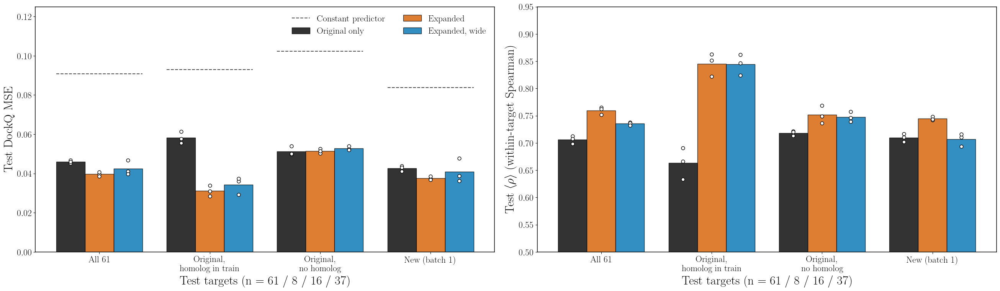

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(26, 7.5), constrained_layout=True)
groups = ['all'] + GROUPS; x = np.arange(len(groups)); w = .26
for ax, col in ((a1, 'mse'), (a2, 'macro_rho')):
    for k, arm in enumerate(ARMS):
        m = metrics[(metrics.stage == MAIN) & (metrics.split == 'test') & (metrics.arm == arm)]
        means = [m[m.group == g][col].mean() for g in groups]
        ax.bar(x + (k - 1) * w, means, w, color=COLOR[arm], alpha=.8, edgecolor='black', lw=1, label=LABEL[arm])
        for i, g in enumerate(groups):
            ax.scatter(np.full(len(SEEDS), x[i] + (k - 1) * w), m[m.group == g][col], color='white', edgecolor='black',
                       s=40, zorder=5, lw=1)
    ax.set_xticks(x, [GROUP_LABEL[g].replace('\n', ' ') if g == 'all' else GROUP_LABEL[g] for g in groups])
    ax.set_xlabel(f'Test targets (n = 61 / {group_counts["orig_homolog"]} / {group_counts["orig_clean"]} / {group_counts["new"]})')
for i, g in enumerate(groups):
    a1.hlines(REF[g]['const_mse'], i - 1.5 * w, i + 1.5 * w, color='0.3', ls='--', lw=1.5,
              label='Constant predictor' if i == 0 else None)
a1.set_ylabel('Test DockQ MSE'); a2.set_ylabel(r'Test $\langle\rho\rangle$ (within-target Spearman)')
a2.set_ylim(.5, .95); a1.set_ylim(0, .125); a1.legend(frameon=False, loc='upper right', ncol=2)
save(fig, 'test_metrics_by_group')

## Paired per-target effects

For each test target, the seed-mean $\rho$ (and MSE) of one arm minus another, at the main comparison stage.
Mean over targets with a 95\% bootstrap interval (10,000 resamples of targets). Positive $\Delta\rho$ and
$-\Delta$MSE favour the first arm.

In [8]:
pt = per_target[(per_target.stage == MAIN) & (per_target.split == 'test')]
pt_mean = pt.groupby(['arm', 'target_id', 'group'])[['rho', 'mse', 'top1']].mean().reset_index()
rng = np.random.default_rng(0)
def boot(v, n=10_000):
    v = np.asarray(v); idx = rng.integers(0, len(v), (n, len(v)))
    return v.mean(), *np.percentile(v[idx].mean(1), [2.5, 97.5])
PAIRS = [('expanded', 'original_only'), ('expanded_large', 'original_only'), ('expanded_large', 'expanded')]
eff, deltas = [], {}
for a, b in PAIRS:
    wide = pt_mean.pivot_table(index=['target_id', 'group'], columns='arm', values=['rho', 'mse', 'top1'])
    d = pd.DataFrame({'drho': wide[('rho', a)] - wide[('rho', b)], 'dmse': -(wide[('mse', a)] - wide[('mse', b)]),
                      'dtop1': wide[('top1', a)] - wide[('top1', b)]}).reset_index()
    deltas[a, b] = d
    for grp in ['all'] + GROUPS:
        sub = d if grp == 'all' else d[d.group == grp]
        for metric in ('drho', 'dmse', 'dtop1'):
            mean, lo, hi = boot(sub[metric])
            eff.append(dict(comparison=f'{a} vs {b}', group=grp, metric=metric, n=len(sub), mean=mean, lo=lo, hi=hi,
                            favourable=int((sub[metric] > 0).sum())))
eff = pd.DataFrame(eff); eff.to_csv(EXPORT / 'paired_effects.csv', index=False)
display(eff.pivot_table(index=['comparison', 'group'], columns='metric', values='mean', sort=False).round(4))
display(eff[eff.metric == 'drho'].set_index(['comparison', 'group'])[['n', 'mean', 'lo', 'hi', 'favourable']].round(4))

metric                                          drho    dmse   dtop1
comparison                      group                               
expanded vs original_only       all           0.0537  0.0073  0.0489
                                orig_homolog  0.1820  0.0320  0.1270
                                orig_clean    0.0332  0.0000  0.0885
                                new           0.0348  0.0051  0.0150
expanded_large vs original_only all           0.0295  0.0045  0.0178
                                orig_homolog  0.1808  0.0285  0.1738
                                orig_clean    0.0293 -0.0014  0.0335
                                new          -0.0032  0.0019 -0.0227
expanded_large vs expanded      all          -0.0242 -0.0028 -0.0312
                                orig_homolog -0.0011 -0.0035  0.0468
                                orig_clean   -0.0039 -0.0015 -0.0550
                                new          -0.0380 -0.0032 -0.0377

n    mean      lo      hi  \
comparison                      group                                      
expanded vs original_only       all           61  0.0537  0.0241  0.0876   
                                orig_homolog   8  0.1820  0.0803  0.3326   
                                orig_clean    16  0.0332 -0.0341  0.1043   
                                new           37  0.0348  0.0117  0.0593   
expanded_large vs original_only all           61  0.0295 -0.0016  0.0638   
                                orig_homolog   8  0.1808  0.0712  0.3345   
                                orig_clean    16  0.0293 -0.0154  0.0769   
                                new           37 -0.0032 -0.0365  0.0262   
expanded_large vs expanded      all           61 -0.0242 -0.0431 -0.0053   
                                orig_homolog   8 -0.0011 -0.0266  0.0185   
                                orig_clean    16 -0.0039 -0.0410  0.0446   
                                new           37 -0.0380 -0.0617 -0.0180   

                                              favourable  
comparison                      group                     
expanded vs original_only       all                   46  
                                orig_homolog           8  
                                orig_clean            11  
                                new                   27  
expanded_large vs original_only all                   38  
                                orig_homolog           7  
                                orig_clean            12  
                                new                   19  
expanded_large vs expanded      all                   22  
                                orig_homolog           5  
                                orig_clean             7  
                                new                   10

### Expanded vs original only, target by target

Each point is one test target ($\Delta\rho$, seed means), by group; bars are the group mean with its bootstrap
interval. The homolog group shows how much of the gain on original targets comes from their training-only homologs.

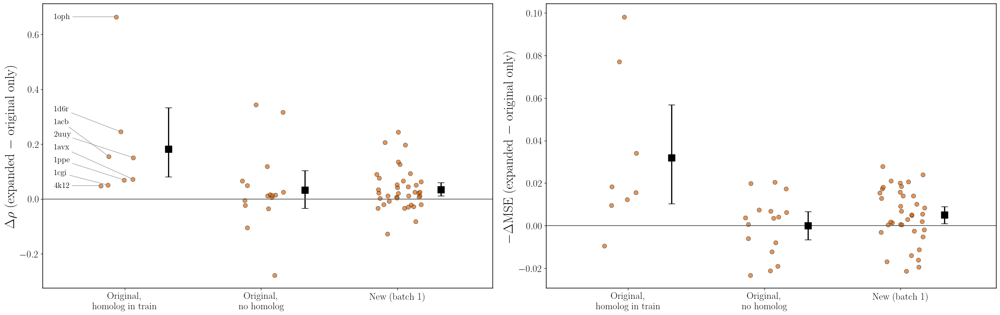

In [9]:
d = deltas['expanded', 'original_only']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(24, 7.5), constrained_layout=True)
jitter = pd.Series(rng.uniform(-.18, .18, len(d)), index=d.index)
for ax, col, ylab in ((a1, 'drho', r'$\Delta\rho$ (expanded $-$ original only)'),
                      (a2, 'dmse', r'$-\Delta$MSE (expanded $-$ original only)')):
    for i, g in enumerate(GROUPS):
        v = d[d.group == g][col].to_numpy()
        ax.scatter(i + jitter[d.group == g], v, s=55, color=COLOR['expanded'], alpha=.65, edgecolor='black', lw=.6)
        e = eff[(eff.comparison == 'expanded vs original_only') & (eff.group == g) & (eff.metric == col)].iloc[0]
        ax.errorbar(i + .32, e['mean'], yerr=[[e['mean'] - e.lo], [e.hi - e['mean']]], fmt='s', ms=11, color='black',
                    capsize=6, lw=2)
    ax.axhline(0, color='0.3', lw=1.2); ax.set_xticks(range(len(GROUPS)), [GROUP_LABEL[g] for g in GROUPS])
    ax.set_ylabel(ylab); ax.set_xlim(-.6, len(GROUPS) - .3)
# label the homolog targets in a spaced column left of their points, with leader lines
h = d[d.group == 'orig_homolog'].sort_values('drho')
span = np.subtract(*a1.get_ylim()[::-1]); gap = .045 * span
ys = []
for y in h.drho:
    ys.append(max(y, ys[-1] + gap) if ys else y)
for (idx, r), y in zip(h.iterrows(), ys):
    a1.annotate(r.target_id, xy=(jitter[idx], r.drho), xytext=(-.52, y), fontsize=14, va='center', ha='left',
                arrowprops=dict(arrowstyle='-', color='0.5', lw=.7))
a1.set_xlim(-.6, len(GROUPS) - .3)
save(fig, 'paired_expanded_vs_original')

## Comparison with Rosetta, ZRank2 and PyDock

The original-only and expanded GATE models against three classical scoring functions on the same 61 test targets.
For every target, each method is evaluated on **exactly the decoys GATE scored** (all 61 targets match 100\% of
their decoys, with identical DockQ labels).

- **Sources.** Original targets: the Chapter 3 balanced per-decoy tables (main dataset; repeated decoys counted
  once) or the raw `bm_55_scoring` files parsed with `ch3_comparison/raw_score_parsers.py` (BM5.5). New targets: the
  target-expansion score tables (`results/scores/<pdb>_{sampled,random}_scores.csv`).
- **Sign.** $\rho$ is oriented so that **higher is better** for every method: the three energy scores are negated
  (the Chapter 3 figures use the opposite sign). Top-1 is the true DockQ of the decoy each method ranks best
  (lowest energy, highest predicted DockQ).
- **GATE.** Per target, the mean over the three seeds, at the final checkpoint once both of these arms have finished
  (otherwise both at epoch 10; printed below). This section can therefore be at a later stage than the three-arm
  comparisons above.
- **Rosetta caveat.** For original targets the Rosetta score is that of the Rosetta-relaxed models (Chapter 3);
  for new targets it is `score_jd2` (ref2015) on the GROMACS-minimized models. Within-target $\rho$ is comparable,
  absolute scores are not.

In [10]:
import sys
sys.path.insert(0, str(GATE / 'ch3_comparison'))
from raw_score_parsers import PARSERS, parse_dockq, base_key

BALANCED = Path('/scratch/uniformly_sampled_ppi_data/all_supersampled_balanced_datasets 3/all_supersampled_balanced_datasets')
BM55 = Path('/scratch/ppi_scoring_data/bm_55_scoring')
NEW_SCORES = Path('/scratch/ppi_target_expansion/results/scores')
CLASSICAL = ['Rosetta', 'ZRank2', 'PyDock']
GATE_ARMS = ['original_only', 'expanded']
SF_STAGE = stage_for(GATE_ARMS)
METHODS = GATE_ARMS + CLASSICAL
MLABEL = {**{a: f'GATE, {LABEL[a].lower()}' for a in GATE_ARMS}, 'Rosetta': 'Rosetta', 'ZRank2': 'ZRank2', 'PyDock': 'PyDock'}
MCOLOR = {**{a: COLOR[a] for a in GATE_ARMS}, 'Rosetta': '#228B22', 'ZRank2': '#191970', 'PyDock': '#DAA520'}

def score_table(t):
    """Per-decoy DockQ + classical scores for one target, each decoy name once (ambiguous names dropped)."""
    if t in new_targets:
        tab = pd.concat([pd.read_csv(NEW_SCORES / f'{t}_{k}_scores.csv', index_col=0) for k in ('sampled', 'random')])
        source = 'new'
    elif (BALANCED / f'{t}_supersampled_balanced_scores.csv').exists():
        tab = pd.read_csv(BALANCED / f'{t}_supersampled_balanced_scores.csv'); source = 'main'
    else:
        d = BM55 / f'scores_sampled_{t}'; frames = []
        files = {'ZRank': 'zrank_files_{k}_{t}.txt.zr.out', 'Rosetta': 'rosetta_scores_{k}_{t}.txt',
                 'PyDock': 'pydock_scores_{t}_{k}.txt'}
        parser = {'ZRank': 'ZRank2', 'Rosetta': 'Rosetta', 'PyDock': 'PyDock'}
        for kind in ('sampled', 'random'):
            dq = {base_key(n): v for n, v in parse_dockq(d / f'dockq_scores_{t}_{kind}.txt').items()}
            cols = {c: {base_key(n): v for n, v in PARSERS[parser[c]](d / f.format(k=kind, t=t)).items()} for c, f in files.items()}
            frames.append(pd.DataFrame({'Decoy': list(dq), 'DockQ': list(dq.values()),
                                        **{c: [cols[c].get(n, np.nan) for n in dq] for c in files}}))
        tab = pd.concat(frames, ignore_index=True); source = 'bm55'
    tab = tab.rename(columns={'Decoy': 'decoy', 'ZRank': 'ZRank2'})[['decoy', 'DockQ'] + CLASSICAL]
    conflicting = tab.groupby('decoy').nunique(dropna=False).max(axis=1) > 1
    return tab[~tab.decoy.isin(conflicting[conflicting].index)].drop_duplicates('decoy'), source

def top1(dockq, score, names):
    return dockq[np.lexsort((names, -score))[0]]

cmp_rows, cover = [], []
for t in sorted(ref['test'].target_id.unique()):
    tab, source = score_table(t)
    ours = ref['test'][ref['test'].target_id == t][['graph_name', 'true_target']]
    j = ours.merge(tab, left_on='graph_name', right_on='decoy', how='left')
    cover.append(dict(target=t, source=source, decoys=len(ours), matched=j.DockQ.notna().mean(),
                      max_dockq_diff=(j.DockQ - j.true_target).abs().max()))
    j = j[j.DockQ.notna() & j[CLASSICAL].notna().all(axis=1)]
    if (j.DockQ - j.true_target).abs().max() > 1e-3:
        raise ValueError(f'{t}: score-table DockQ differs from our labels')
    y, names = j.true_target.to_numpy(), j.graph_name.to_numpy()
    for m in CLASSICAL:
        s = -j[m].to_numpy()   # energies: lower is better -> negate so higher is better
        cmp_rows.append(dict(target=t, group=group_of(t), source=source, method=m, n=len(j),
                             rho=spearmanr(s, y).statistic, top1=top1(y, s, names)))
    for a in GATE_ARMS:
        for seed in SEEDS:
            p = preds[a, seed, SF_STAGE]['test']; p = p[p.target_id == t].set_index('graph_name').loc[names, 'predicted_target'].to_numpy()
            cmp_rows.append(dict(target=t, group=group_of(t), source=source, method=a, seed=seed, n=len(j),
                                 rho=spearmanr(p, y).statistic, top1=top1(y, p, names)))
cmp_all = pd.DataFrame(cmp_rows); cover = pd.DataFrame(cover)
cmp_t = cmp_all.groupby(['method', 'target', 'group', 'source'])[['rho', 'top1']].mean().reset_index()
cmp_all.to_csv(EXPORT / 'scoring_functions_per_target.csv', index=False)
print(f'GATE stage in this section: {SF_STAGE}')
print(f"{len(cover)} test targets ({cover.source.value_counts().to_dict()}); decoys matched: min {cover.matched.min():.0%}; "
      f"max |DockQ difference| {cover.max_dockq_diff.max():.1e}.")
tabs = {}
for grp in ['all'] + GROUPS:
    sub = cmp_t if grp == 'all' else cmp_t[cmp_t.group == grp]
    tabs[grp] = sub.groupby('method')[['rho', 'top1']].agg(['mean', 'std']).loc[METHODS]
summary_sf = pd.concat(tabs, axis=0, names=['group']); summary_sf.to_csv(EXPORT / 'scoring_functions_summary.csv')
display(summary_sf.round(3))

GATE stage in this section: final
61 test targets ({'new': 37, 'main': 12, 'bm55': 12}); decoys matched: min 100%; max |DockQ difference| 3.0e-08.


rho          top1       
                             mean    std   mean    std
group        method                                   
all          original_only  0.707  0.195  0.538  0.306
             expanded       0.760  0.171  0.599  0.297
             Rosetta        0.423  0.297  0.815  0.202
             ZRank2         0.746  0.133  0.593  0.296
             PyDock         0.646  0.295  0.536  0.329
orig_homolog original_only  0.639  0.231  0.486  0.289
             expanded       0.844  0.074  0.651  0.274
             Rosetta        0.596  0.164  0.778  0.077
             ZRank2         0.659  0.145  0.383  0.351
             PyDock         0.438  0.459  0.383  0.370
orig_clean   original_only  0.727  0.277  0.576  0.368
             expanded       0.750  0.281  0.637  0.309
             Rosetta        0.726  0.174  0.741  0.272
             ZRank2         0.818  0.123  0.692  0.258
             PyDock         0.679  0.281  0.572  0.339
new          original_only  0.712  0.140  0.532  0.287
             expanded       0.746  0.113  0.572  0.300
             Rosetta        0.254  0.229  0.856  0.178
             ZRank2         0.733  0.123  0.595  0.283
             PyDock         0.678  0.245  0.554  0.316

### Bar charts

Bars: mean over targets in each group; error bars: SD over targets; white points (GATE): the three seeds' group
means. Left: $\langle\rho\rangle$. Right: mean top-1 DockQ, with dashed lines for a random pick (lower) and the
best decoy (upper). Group sizes: 61 / 8 / 16 / 37 targets.

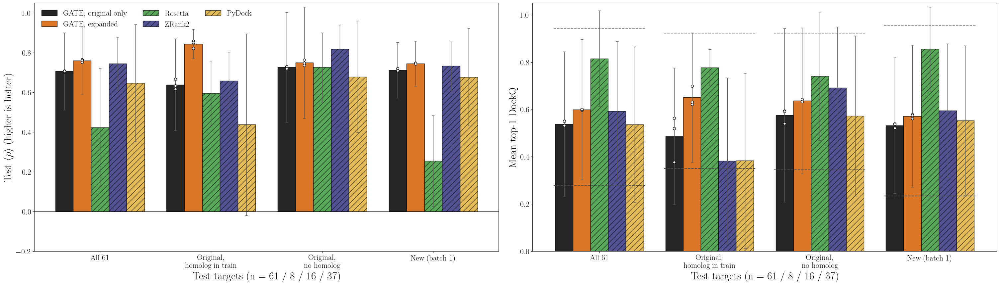

**Paired per-target Δρ, GATE minus scoring function** (95% bootstrap CI; targets where GATE is better)

n   drho     lo     hi  gate_better
gate          versus  group                                             
original_only Rosetta all           61  0.284  0.198  0.370           49
                      orig_homolog   8  0.044 -0.177  0.249            4
                      orig_clean    16  0.000 -0.107  0.101           10
                      new           37  0.458  0.369  0.547           35
expanded      Rosetta all           61  0.337  0.258  0.417           56
                      orig_homolog   8  0.249  0.124  0.381            8
                      orig_clean    16  0.023 -0.095  0.119           12
                      new           37  0.492  0.406  0.576           36
original_only ZRank2  all           61 -0.039 -0.079 -0.001           27
                      orig_homolog   8 -0.020 -0.107  0.044            5
                      orig_clean    16 -0.092 -0.186 -0.002            6
                      new           37 -0.021 -0.065  0.028           16
expanded      ZRank2  all           61  0.014 -0.029  0.055           36
                      orig_homolog   8  0.185  0.101  0.269            8
                      orig_clean    16 -0.069 -0.174  0.006            9
                      new           37  0.013 -0.026  0.059           19
original_only PyDock  all           61  0.060  0.003  0.123           31
                      orig_homolog   8  0.202 -0.032  0.484            4
                      orig_clean    16  0.048 -0.000  0.101           13
                      new           37  0.035 -0.038  0.117           14
expanded      PyDock  all           61  0.113  0.045  0.189           38
                      orig_homolog   8  0.406  0.125  0.734            7
                      orig_clean    16  0.070 -0.001  0.145           13
                      new           37  0.068 -0.003  0.151           18

In [11]:
groups = ['all'] + GROUPS; x = np.arange(len(groups)); w = .16
fig, (a1, a2) = plt.subplots(1, 2, figsize=(30, 8.5), constrained_layout=True)
for ax, col in ((a1, 'rho'), (a2, 'top1')):
    for k, m in enumerate(METHODS):
        mu = [tabs[g].loc[m, (col, 'mean')] for g in groups]; sd = [tabs[g].loc[m, (col, 'std')] for g in groups]
        pos = x + (k - 2) * w
        ax.bar(pos, mu, w, yerr=sd, color=MCOLOR[m], alpha=.85 if m in GATE_ARMS else .75, edgecolor='black', lw=1,
               hatch='' if m in GATE_ARMS else '//', capsize=3, error_kw=dict(lw=1, ecolor='0.35'), label=MLABEL[m])
        if m in GATE_ARMS:
            seed_means = cmp_all[cmp_all.method == m].groupby(['seed', 'group'])[col].mean().unstack()
            for i, g in enumerate(groups):
                v = cmp_all[cmp_all.method == m].groupby('seed')[col].mean() if g == 'all' else seed_means[g]
                ax.scatter(np.full(len(v), pos[i]), v, color='white', edgecolor='black', s=32, lw=1, zorder=5)
    ax.set_xticks(x, [GROUP_LABEL[g] for g in groups])
    ax.set_xlabel(f'Test targets (n = 61 / {group_counts["orig_homolog"]} / {group_counts["orig_clean"]} / {group_counts["new"]})')
for i, g in enumerate(groups):
    for key in ('random_top1', 'oracle_top1'):
        a2.hlines(REF[g][key], i - 2.6 * w, i + 2.6 * w, color='0.3', ls='--', lw=1.4)
a1.axhline(0, color='black', lw=1)
a1.set_ylabel(r'Test $\langle\rho\rangle$ (higher is better)'); a2.set_ylabel('Mean top-1 DockQ')
a1.set_ylim(-.2, 1.05); a2.set_ylim(0, 1.05)
a1.legend(frameon=False, loc='upper left', ncol=3, fontsize=17)
save(fig, 'scoring_functions_bars')

wins = []
for m in CLASSICAL:
    for a in GATE_ARMS:
        w_ = cmp_t.pivot_table(index=['target', 'group'], columns='method', values='rho').reset_index()
        for grp in ['all'] + GROUPS:
            sub = w_ if grp == 'all' else w_[w_.group == grp]
            d = sub[a] - sub[m]; mean, lo, hi = boot(d)
            wins.append(dict(gate=a, versus=m, group=grp, n=len(sub), drho=mean, lo=lo, hi=hi, gate_better=int((d > 0).sum())))
wins = pd.DataFrame(wins); wins.to_csv(EXPORT / 'gate_vs_scoring_functions.csv', index=False)
display(Markdown('**Paired per-target Δρ, GATE minus scoring function** (95% bootstrap CI; targets where GATE is better)'))
display(wins.set_index(['gate', 'versus', 'group']).round(3))

### Average $\langle\rho\rangle_t$ over all test targets, in the style of Fig. 7(a) of the PRE paper

All 61 test targets, every method on the same decoys. As in the paper, $\rho$ uses the **raw** scores (more negative
is better): the energy scores are used as is, and GATE's predicted DockQ is negated. Markers are
$\langle\rho\rangle_t$ (mean over targets), vertical lines $\pm 1$ SD over targets; methods are ordered from best to
worst. Paper markers and colours for ZRank2, PyDock and Rosetta.

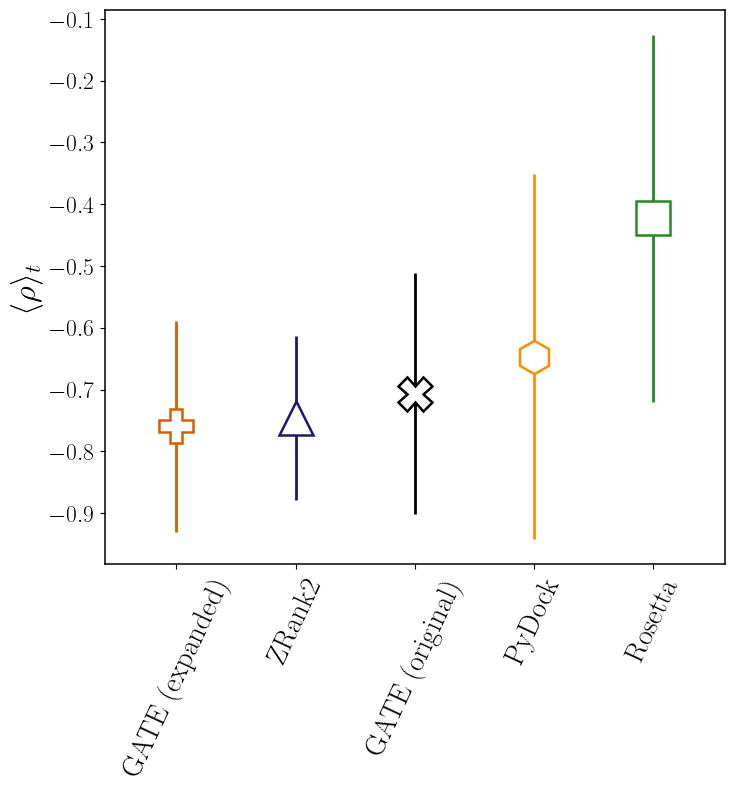

,mean rho (paper sign),SD over targets,targets
method,,,
expanded,-0.760,0.171,61
ZRank2,-0.746,0.133,61
original_only,-0.707,0.195,61
PyDock,-0.646,0.295,61
Rosetta,-0.423,0.297,61


In [12]:
F7 = {'expanded': dict(label='GATE (expanded)', marker='P', color=COLOR['expanded']),
      'original_only': dict(label='GATE (original)', marker='X', color='black'),
      'ZRank2': dict(label='ZRank2', marker='^', color='#191970'),
      'PyDock': dict(label='PyDock', marker='h', color='#FF8C00'),
      'Rosetta': dict(label='Rosetta', marker='s', color='#228B22')}
paper = cmp_t.assign(rho_paper=-cmp_t.rho).groupby('method').rho_paper.agg(['mean', 'std', 'size'])
order = paper['mean'].sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(8, 7.2))
for i, m in enumerate(order):
    st = F7[m]
    ax.vlines(i, paper.loc[m, 'mean'] - paper.loc[m, 'std'], paper.loc[m, 'mean'] + paper.loc[m, 'std'], color=st['color'], lw=2)
    ax.plot(i, paper.loc[m, 'mean'], marker=st['marker'], ms=24, mfc='white', mec=st['color'], mew=1.8, ls='none', zorder=5)
ax.set_xticks(range(len(order)), [F7[m]['label'] for m in order], rotation=65, ha='center', fontsize=21)
ax.set_xlim(-.6, len(order) - .4); ax.set_ylabel(r'$\langle \rho \rangle_t$', fontsize=24)
save(fig, 'fig7a_style_average_rho')
display(paper.loc[order].rename(columns={'mean': 'mean rho (paper sign)', 'std': 'SD over targets', 'size': 'targets'}).round(3))

### Per-target $\rho$, in the style of Fig. 4 of the PRE paper

Every test target, every method on the same decoys, raw-score $\rho$ as in the paper (more negative is better; GATE's
predicted DockQ negated; GATE = mean over the three seeds). Targets are ordered left to right by increasing
$\langle\rho\rangle$ of **ZRank2, PyDock and Rosetta** (black line; black vertical lines = SD over those three), so
the ordering is a classical-difficulty scale independent of GATE. GATE is overlaid in filled gray (dark: expanded;
light: original only). Tick labels are the target PDB IDs; their group (H/O/N) is in the CSV export.

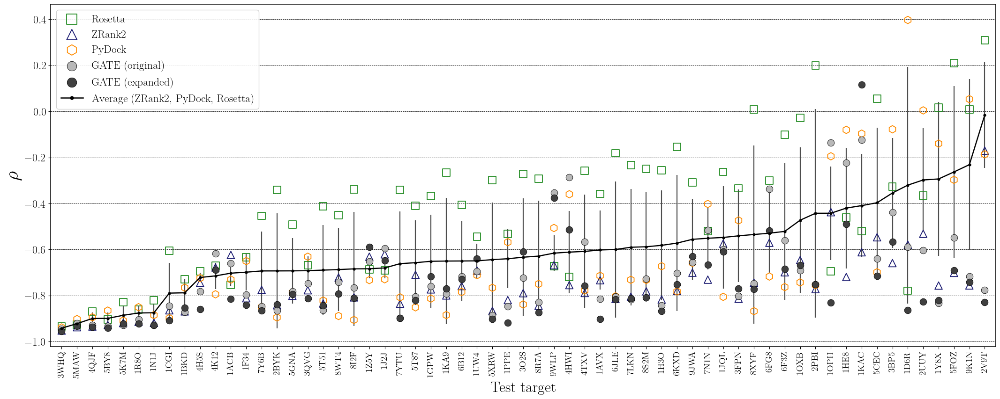

Targets (of 61) where GATE has a more negative $\rho$ than each scoring function:

,Rosetta,ZRank2,PyDock
GATE expanded better on,56,36,38
GATE original better on,49,27,31


In [13]:
F4 = {'ZRank2': dict(marker='^', color='#191970', label='ZRank2'),
      'Rosetta': dict(marker='s', color='#228B22', label='Rosetta'),
      'PyDock': dict(marker='h', color='#FF8C00', label='PyDock'),
      'expanded': dict(marker='o', color='0.25', label='GATE (expanded)'),
      'original_only': dict(marker='o', color='0.72', label='GATE (original)')}
w4 = cmp_t.assign(rho_paper=-cmp_t.rho).pivot_table(index='target', columns='method', values='rho_paper')
w4['avg'] = w4[CLASSICAL].mean(axis=1); w4['sd'] = w4[CLASSICAL].std(axis=1, ddof=0)
w4 = w4.sort_values('avg'); x4 = np.arange(1, len(w4) + 1)
w4.assign(order=x4, group=w4.index.map(group_of)).to_csv(EXPORT / 'fig4_style_per_target_rho.csv')

fig, ax = plt.subplots(figsize=(26, 9.5))
for m in CLASSICAL:
    st = F4[m]
    ax.scatter(x4, w4[m], marker=st['marker'], s=130, facecolors='none', edgecolors=st['color'], lw=1.3, label=st['label'], zorder=3)
for m in ['original_only', 'expanded']:
    st = F4[m]
    ax.scatter(x4, w4[m], marker=st['marker'], s=110, color=st['color'], edgecolors='black', lw=.6, label=st['label'], zorder=4)
ax.vlines(x4, w4.avg - w4.sd, w4.avg + w4.sd, color='0.3', lw=1.6, zorder=2)
ax.plot(x4, w4.avg, color='black', marker='.', ms=7, lw=1.8, label=r'Average (ZRank2, PyDock, Rosetta)', zorder=5)
ax.yaxis.grid(True, ls='--', lw=.6, color='black'); ax.set_axisbelow(True)
ax.set_xlim(.3, len(w4) + .7); ax.set_xticks(x4, [t.upper() for t in w4.index], rotation=90, fontsize=14)
ax.set_xlabel('Test target'); ax.set_ylabel(r'$\rho$', fontsize=30)
ax.legend(loc='upper left', fontsize=17, markerscale=1.4, frameon=True, framealpha=.9)
save(fig, 'fig4_style_per_target_rho')

beat = pd.DataFrame({m: [(w4[g] < w4[m]).sum() for g in ('expanded', 'original_only')] for m in CLASSICAL},
                    index=['GATE expanded better on', 'GATE original better on'])
display(Markdown(f'Targets (of {len(w4)}) where GATE has a more negative $\\rho$ than each scoring function:'))
display(beat)

## Epoch 10 vs final

Runs with both evaluations: the epoch of the selected checkpoint and test metrics at each stage. If the best
validation checkpoint does not move after epoch 10, the final numbers equal the snapshot.

In [14]:
both = [(a, s) for a in ARMS for s in SEEDS if (a, s, 'epoch10') in preds and (a, s, 'final') in preds]
if both:
    m = metrics[(metrics.split == 'test') & (metrics.group == 'all')].set_index(['arm', 'seed', 'stage'])
    tab = pd.DataFrame([dict(arm=a, seed=s, **{f'{c}_{st}': m.loc[(a, s, st), c] for st in ('epoch10', 'final')
                                                for c in ('best_epoch', 'mse', 'macro_rho', 'top1')}) for a, s in both])
    tab.to_csv(EXPORT / 'epoch10_vs_final.csv', index=False)
    display(tab.round(4))
    display(tab.groupby('arm')[[c for c in tab.columns if c not in ('arm', 'seed')]].mean().round(4))
else:
    print('No run has both an epoch-10 and a final evaluation yet.')

,arm,seed,best_epoch_epoch10,mse_epoch10,macro_rho_epoch10,top1_epoch10,best_epoch_final,mse_final,macro_rho_final,top1_final
0,original_only,7,5,0.0467,0.6983,0.5375,15,0.0478,0.7032,0.5316
1,original_only,17,6,0.0451,0.7124,0.5365,12,0.0483,0.7092,0.5497
2,original_only,27,6,0.0459,0.7073,0.5318,6,0.0459,0.7073,0.5318
3,expanded,7,10,0.0398,0.7650,0.5554,12,0.0399,0.7650,0.6002
4,expanded,17,7,0.0385,0.7621,0.5968,7,0.0385,0.7621,0.5968
5,expanded,27,4,0.0406,0.7520,0.6004,4,0.0406,0.7520,0.6004


,best_epoch_epoch10,mse_epoch10,macro_rho_epoch10,top1_epoch10,best_epoch_final,mse_final,macro_rho_final,top1_final
arm,,,,,,,,
expanded,7.0000,0.0397,0.7597,0.5842,7.6667,0.0397,0.7597,0.5991
original_only,5.6667,0.0459,0.7060,0.5352,11.0000,0.0473,0.7066,0.5377


## Observed vs predicted DockQ on the test set

Each panel pools the three seeds of one arm (main comparison stage) over all 61 test targets. Shading is the log
count of decoys; dashed diagonal = perfect agreement; dotted lines = CAPRI thresholds; coloured line = mean
prediction in bins of observed DockQ.

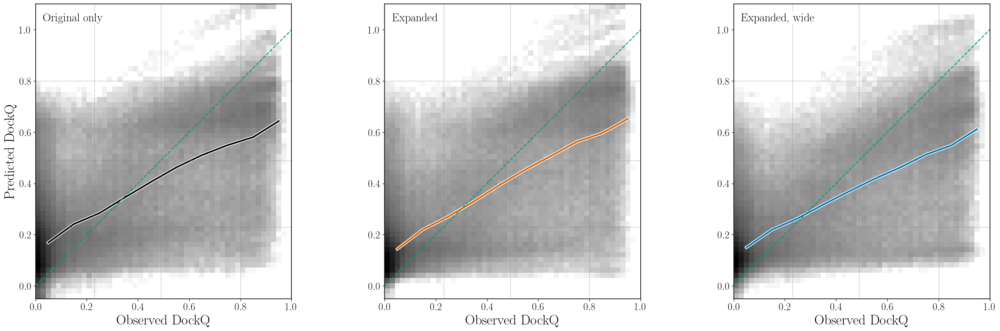

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5), sharex=True, sharey=True, constrained_layout=True)
edges = np.linspace(0, 1, 11); mids = (edges[:-1] + edges[1:]) / 2
for ax, arm in zip(axes, ARMS):
    pr = pd.concat([preds[arm, s, MAIN]['test'] for s in SEEDS])
    ax.hist2d(pr.true_target, pr.predicted_target.clip(-.05, 1.1), bins=[np.linspace(0, 1, 51), np.linspace(-.05, 1.1, 58)],
              cmap='Greys', norm=LogNorm(vmin=1), rasterized=True)
    means = pr.groupby(pd.cut(pr.true_target, edges, include_lowest=True), observed=False).predicted_target.mean()
    ax.plot(mids, means.to_numpy(), color='white', lw=5); ax.plot(mids, means.to_numpy(), color=COLOR[arm], lw=2.6)
    ax.plot([0, 1], [0, 1], color='#009E73', ls='--', lw=1.5)
    for t in CAPRI:
        ax.axvline(t, color='0.5', ls=':', lw=1); ax.axhline(t, color='0.5', ls=':', lw=1)
    ax.text(.03, .97, LABEL[arm], transform=ax.transAxes, va='top', fontsize=19,
            bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=2))
    ax.set(xlim=(0, 1), ylim=(-.05, 1.1)); ax.set_aspect('equal', adjustable='box'); ax.set_xlabel('Observed DockQ')
    ax.tick_params(labelleft=True)
axes[0].set_ylabel('Predicted DockQ')
save(fig, 'test_observed_vs_predicted')

### Every test target

Per-target panels use, for each arm, the seed with the lowest **validation** DockQ MSE at the main comparison stage
(chosen on validation, not test, so the panels are not flattered by test-set selection). Each translucent circle is
one decoy; shared axes; dashed line = perfect agreement; the annotation gives the target, its group (H = original
with a training-only homolog in the expanded train set, O = original without, N = new) and the within-target Spearman
$\rho$. Targets are ordered by group, then by name.

Panel seed (lowest validation MSE): {'original_only': 27, 'expanded': 17, 'expanded_large': 17}


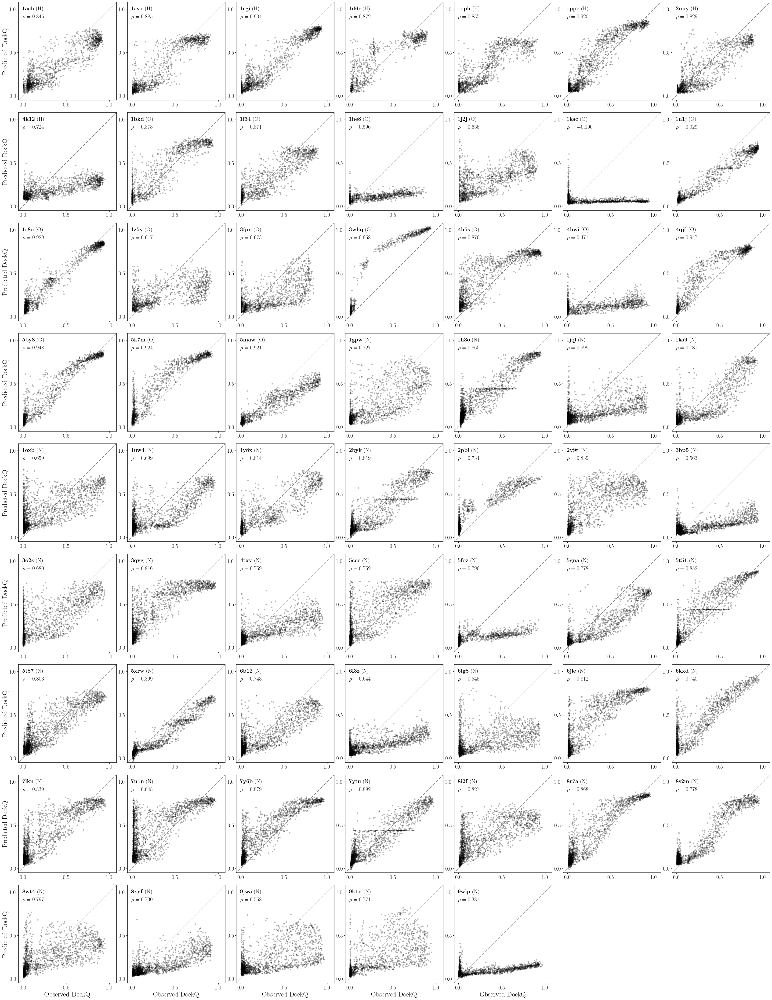

In [16]:
val_mse = metrics[(metrics.stage == MAIN) & (metrics.split == 'validation') & (metrics.group == 'all')]
PANEL_SEED = {a: int(val_mse[val_mse.arm == a].set_index('seed').mse.idxmin()) for a in ARMS}
print('Panel seed (lowest validation MSE):', PANEL_SEED)
TAG = {'orig_homolog': 'H', 'orig_clean': 'O', 'new': 'N'}
panel_targets = sorted(ref['test'].target_id.unique(), key=lambda t: (GROUPS.index(group_of(t)), t))
lim = (-.05, 1.08)

def target_grid(arms, name, ncols=7):
    sel = {a: preds[a, PANEL_SEED[a], MAIN]['test'] for a in arms}
    nrows = int(np.ceil(len(panel_targets) / ncols))
    with mpl.rc_context({'axes.labelsize': 21, 'xtick.labelsize': 17, 'ytick.labelsize': 17}):
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.7 * ncols, 4.75 * nrows), sharex=True, sharey=True,
                                 constrained_layout=True)
        for ax, t in zip(axes.flat, panel_targets):
            texts = [(rf'\textbf{{{t}}} ({TAG[group_of(t)]})', 'black')]
            for a in arms:
                g = sel[a][sel[a].target_id == t]
                rho = spearmanr(g.true_target, g.predicted_target).statistic
                color = 'black' if len(arms) == 1 else COLOR[a]
                ax.scatter(g.true_target, g.predicted_target.clip(*lim), color=color, alpha=.25 if len(arms) > 1 else .3,
                           s=14 if len(arms) > 1 else 18, edgecolors='none', rasterized=True)
                # usetex drops \textcolor, so each arm's rho is its own text object in that arm's colour
                texts.append((rf'$\rho = {rho:.3f}$' if len(arms) == 1 else rf'{SHORT[a]} $\rho = {rho:.3f}$',
                              'black' if len(arms) == 1 else COLOR[a]))
            ax.plot(lim, lim, color='0.45', ls='--', lw=1.2)
            for k, (txt, color) in enumerate(texts):
                ax.text(.04, .96 - .085 * k, txt, transform=ax.transAxes, ha='left', va='top', fontsize=17, color=color,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1.5))
            ax.set(xlim=lim, ylim=lim, xticks=[0, .5, 1], yticks=[0, .5, 1]); ax.set_aspect('equal', adjustable='box')
            ax.tick_params(labelbottom=True, labelleft=True)
        for ax in axes[-1]: ax.set_xlabel('Observed DockQ')
        for ax in axes[:, 0]: ax.set_ylabel('Predicted DockQ')
        for ax in list(axes.flat)[len(panel_targets):]:
            ax.set_visible(False)
        if len(arms) > 1:
            handles = [plt.Line2D([], [], marker='o', ls='none', ms=12, color=COLOR[a],
                                  label=f'{LABEL[a]} (seed {PANEL_SEED[a]})') for a in arms]
            fig.legend(handles=handles, loc='lower right', bbox_to_anchor=(.98, .02), frameon=False, fontsize=22)
        save(fig, name)

SHORT = {'original_only': 'orig.', 'expanded': 'exp.', 'expanded_large': 'wide'}
target_grid(['expanded'], f'test_per_target_expanded_seed{PANEL_SEED["expanded"]}')

### Every test target: expanded vs original only

Both arms in each panel (orange: expanded; black: original only; each at its best-validation seed), with each arm's
$\rho$ in its colour.

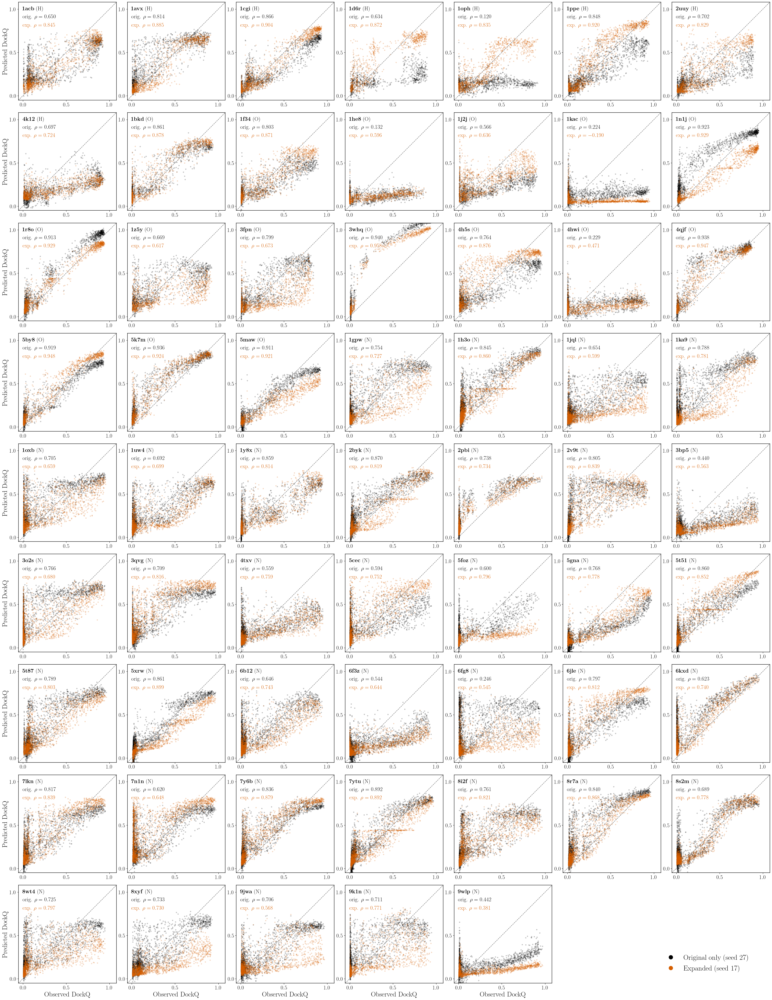

In [17]:
target_grid(['original_only', 'expanded'], 'test_per_target_expanded_vs_original')

## Dissertation figure (grayscale)

Test $\langle\rho\rangle$ by group for the three arms (seed mean $\pm$ SD), main comparison stage.

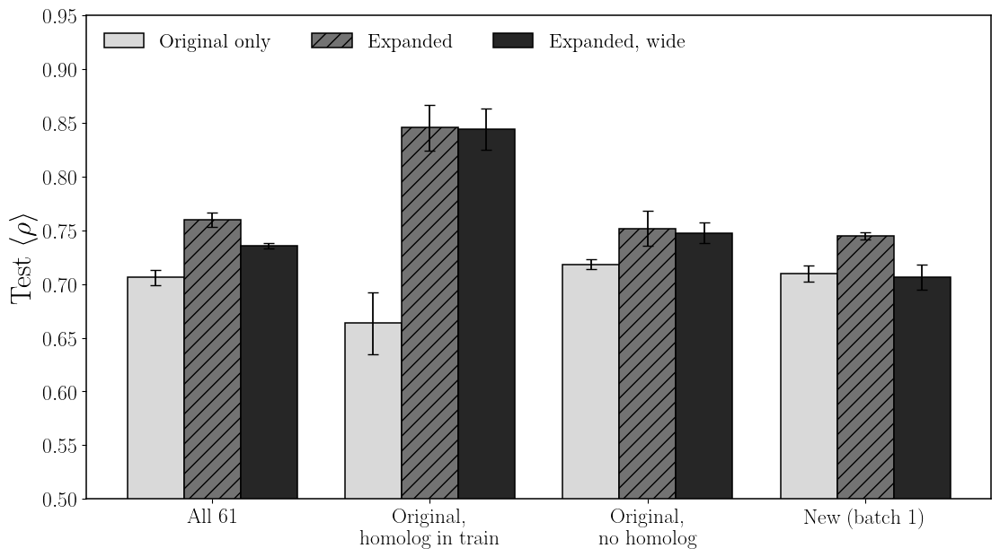

In [18]:
fig, ax = plt.subplots(figsize=(13, 7))
groups = ['all'] + GROUPS; x = np.arange(len(groups)); w = .26
hatch = {'original_only': '', 'expanded': '//', 'expanded_large': ''}
for k, arm in enumerate(ARMS):
    m = metrics[(metrics.stage == MAIN) & (metrics.split == 'test') & (metrics.arm == arm)]
    mu = [m[m.group == g].macro_rho.mean() for g in groups]; sd = [m[m.group == g].macro_rho.std() for g in groups]
    ax.bar(x + (k - 1) * w, mu, w, yerr=sd, color=GRAY[arm], edgecolor='black', lw=1.1, hatch=hatch[arm],
           capsize=4, error_kw=dict(lw=1.3), label=LABEL[arm])
ax.set_xticks(x, [GROUP_LABEL[g] for g in groups]); ax.set_ylim(.5, .95)
ax.set_ylabel(r'Test $\langle\rho\rangle$'); ax.legend(frameon=False, loc='upper left', ncol=3, fontsize=16)
save(fig, 'dissertation_rho_by_group_gray')

## Readout

In [19]:
def ms(stage, split, grp, arm, col, f='.4f'):
    return f"{agg.loc[(stage, split, grp, arm), (col, 'mean')]:{f}} ± {agg.loc[(stage, split, grp, arm), (col, 'std')]:{f}}"
lines = [f'Stage: **{MAIN}**. Seed mean ± SD.', '',
         '| arm | val MSE | test MSE | test ⟨ρ⟩ | ⟨ρ⟩ original, homolog | ⟨ρ⟩ original, no homolog | ⟨ρ⟩ new | test top-1 | selected epoch |',
         '|---|---|---|---|---|---|---|---|---|']
for a in ARMS:
    lines.append(f"| {LABEL[a]} | {ms(MAIN, 'validation', 'all', a, 'mse')} | {ms(MAIN, 'test', 'all', a, 'mse')} | "
                 f"{ms(MAIN, 'test', 'all', a, 'macro_rho', '.3f')} | {ms(MAIN, 'test', 'orig_homolog', a, 'macro_rho', '.3f')} | "
                 f"{ms(MAIN, 'test', 'orig_clean', a, 'macro_rho', '.3f')} | {ms(MAIN, 'test', 'new', a, 'macro_rho', '.3f')} | "
                 f"{ms(MAIN, 'test', 'all', a, 'top1', '.3f')} | {ms(MAIN, 'test', 'all', a, 'best_epoch', '.1f')} |")
lines += ['', f"References (all test targets): constant-predictor MSE {REF['all']['const_mse']:.4f}; random / oracle "
          f"top-1 {REF['all']['random_top1']:.3f} / {REF['all']['oracle_top1']:.3f}.", '',
          'Paired per-target effects (95% bootstrap CI over targets; positive favours the first arm):']
for a, b in PAIRS:
    for grp in ['all'] + GROUPS:
        r = eff[(eff.comparison == f'{a} vs {b}') & (eff.group == grp)].set_index('metric')
        lines.append(f"- {LABEL[a]} vs {LABEL[b]}, {GROUP_LABEL[grp].replace(chr(10), ' ')} (n={int(r.loc['drho', 'n'])}): "
                     f"Δρ {r.loc['drho', 'mean']:+.3f} [{r.loc['drho', 'lo']:+.3f}, {r.loc['drho', 'hi']:+.3f}], "
                     f"−ΔMSE {r.loc['dmse', 'mean']:+.4f} [{r.loc['dmse', 'lo']:+.4f}, {r.loc['dmse', 'hi']:+.4f}], "
                     f"Δtop-1 {r.loc['dtop1', 'mean']:+.3f}")
lines += ['', 'After epoch 10 (validation DockQ MSE improved on the epoch-10 best):']
for a in ARMS:
    q = after[after.arm == a]
    lines.append(f"- {LABEL[a]}: epochs done {q.epochs_done.min()}–{q.epochs_done.max()}; improved in "
                 f"{int(q.improved_after_10.sum())}/{len(q)} seeds; best epochs {', '.join(map(str, q.best_epoch))}")
text = '\n'.join(lines); display(Markdown(text)); _ = (EXPORT / 'readout.md').write_text(text)

Stage: **epoch10**. Seed mean ± SD.

| arm | val MSE | test MSE | test ⟨ρ⟩ | ⟨ρ⟩ original, homolog | ⟨ρ⟩ original, no homolog | ⟨ρ⟩ new | test top-1 | selected epoch |
|---|---|---|---|---|---|---|---|---|
| Original only | 0.0505 ± 0.0010 | 0.0459 ± 0.0008 | 0.706 ± 0.007 | 0.663 ± 0.029 | 0.718 ± 0.005 | 0.710 ± 0.007 | 0.535 ± 0.003 | 5.7 ± 0.6 |
| Expanded | 0.0434 ± 0.0011 | 0.0397 ± 0.0010 | 0.760 ± 0.007 | 0.845 ± 0.021 | 0.752 ± 0.016 | 0.745 ± 0.003 | 0.584 ± 0.025 | 7.0 ± 3.0 |
| Expanded, wide | 0.0485 ± 0.0012 | 0.0426 ± 0.0037 | 0.735 ± 0.003 | 0.844 ± 0.019 | 0.748 ± 0.009 | 0.707 ± 0.012 | 0.553 ± 0.050 | 2.7 ± 2.1 |

References (all test targets): constant-predictor MSE 0.0908; random / oracle top-1 0.278 / 0.941.

Paired per-target effects (95% bootstrap CI over targets; positive favours the first arm):
- Expanded vs Original only, All 61 (n=61): Δρ +0.054 [+0.024, +0.088], −ΔMSE +0.0073 [+0.0026, +0.0126], Δtop-1 +0.049
- Expanded vs Original only, Original, homolog in train (n=8): Δρ +0.182 [+0.080, +0.333], −ΔMSE +0.0320 [+0.0105, +0.0568], Δtop-1 +0.127
- Expanded vs Original only, Original, no homolog (n=16): Δρ +0.033 [-0.034, +0.104], −ΔMSE +0.0000 [-0.0065, +0.0067], Δtop-1 +0.089
- Expanded vs Original only, New (batch 1) (n=37): Δρ +0.035 [+0.012, +0.059], −ΔMSE +0.0051 [+0.0010, +0.0090], Δtop-1 +0.015
- Expanded, wide vs Original only, All 61 (n=61): Δρ +0.029 [-0.002, +0.064], −ΔMSE +0.0045 [-0.0003, +0.0096], Δtop-1 +0.018
- Expanded, wide vs Original only, Original, homolog in train (n=8): Δρ +0.181 [+0.071, +0.334], −ΔMSE +0.0285 [+0.0082, +0.0533], Δtop-1 +0.174
- Expanded, wide vs Original only, Original, no homolog (n=16): Δρ +0.029 [-0.015, +0.077], −ΔMSE -0.0014 [-0.0098, +0.0048], Δtop-1 +0.033
- Expanded, wide vs Original only, New (batch 1) (n=37): Δρ -0.003 [-0.036, +0.026], −ΔMSE +0.0019 [-0.0023, +0.0060], Δtop-1 -0.023
- Expanded, wide vs Expanded, All 61 (n=61): Δρ -0.024 [-0.043, -0.005], −ΔMSE -0.0028 [-0.0049, -0.0009], Δtop-1 -0.031
- Expanded, wide vs Expanded, Original, homolog in train (n=8): Δρ -0.001 [-0.027, +0.019], −ΔMSE -0.0035 [-0.0053, -0.0014], Δtop-1 +0.047
- Expanded, wide vs Expanded, Original, no homolog (n=16): Δρ -0.004 [-0.041, +0.045], −ΔMSE -0.0015 [-0.0077, +0.0042], Δtop-1 -0.055
- Expanded, wide vs Expanded, New (batch 1) (n=37): Δρ -0.038 [-0.062, -0.018], −ΔMSE -0.0032 [-0.0052, -0.0013], Δtop-1 -0.038

After epoch 10 (validation DockQ MSE improved on the epoch-10 best):
- Original only: epochs done 20–20; improved in 2/3 seeds; best epochs 15, 12, 6
- Expanded: epochs done 20–20; improved in 1/3 seeds; best epochs 12, 7, 4
- Expanded, wide: epochs done 16–19; improved in 0/3 seeds; best epochs 1, 2, 5

## Interpretation (epoch-10 snapshot, 27 October 2026)

Written when original only had finished and the expanded arms were at epochs 13--17; revisit when all runs are final.

**More data helps, beyond the leakage.** Over all 61 test targets the expanded arm improves $\langle\rho\rangle$ by
about 0.05 and lowers test MSE by about 14\% (0.040 vs 0.046), with seed spreads far smaller than the gap. The gain
is largest on the 8 original targets whose training-only homologs it saw ($\Delta\rho \approx +0.18$), which is
leakage by design. On the targets without that advantage the effect is smaller but present: $\Delta\rho \approx +0.035$
on the 37 new targets (interval excludes zero) and $\approx +0.03$ on the 16 clean original targets (interval
includes zero, with unchanged MSE but a better top-1 pick). The expanded model also catches more true high-quality
decoys.

**The wider model is not better.** Hidden 128 / latent 64 fits the training DockQ labels much better but its
validation DockQ MSE is best at epochs 1--5 and then rises: it overfits the per-decoy labels. Paired against the
standard width on the same data it is worse on the new targets and no better elsewhere.

**Against the classical scoring functions** (same decoys, $\rho$ oriented higher-is-better). On all 61 targets
the expanded model ranks decoys about as well as ZRank2 ($\langle\rho\rangle$ 0.76 vs 0.75; ahead only on the
homolog group, behind on the 16 clean original targets) and better than PyDock (0.65) and Rosetta (0.42). Rosetta
behaves differently from the rest: the worst ranker overall (0.25 on new targets) but by far the best at picking
the single best decoy (mean top-1 DockQ 0.82 vs 0.58--0.59 for GATE expanded and ZRank2). On the new targets a
median 98\% of its 50 best-scored decoys are medium or high quality, while the incorrect poses get widely scattered
(sometimes very large) energies, which scrambles the overall ranking. GATE's top-1 lags because its predictions
saturate around 0.6--0.8 for many near-native decoys (see the per-target panels), so the top pick among them is
close to arbitrary.

**Ten epochs are about enough.** The original-only runs gained nothing on test between epoch 10 and 20, and the
expanded runs' best validation checkpoints so far are mostly from epochs 4--12.

## Limitations

- **One fold, three seeds.** All arms use stratified fold 1; the differences between arms are paired on the same
  61 test targets, but fold-to-fold variation is not measured.
- **Homolog leakage is part of the expanded arm by design.** Gains on the 8 original test targets with a
  training-only homolog are not generalization to unseen interfaces. The *original, no homolog* and *new* groups are
  the cleaner measure; `gate_run/homolog_leakage_splits/` holds the paired folds that measure the leakage directly.
- **New targets share the preparation pipeline** (GROMACS-minimized models, new DockQ labels) with the new training
  data; a gain only on *new* targets could partly be pipeline matching rather than better interface modelling.
- **More data also means more steps.** At equal epochs the expanded arms take about 3$\times$ more optimizer steps
  than original only.
- **The test set is now spent** for these choices. Later tuning should be judged on validation or on other folds.
- **Epoch-10 numbers are a snapshot**; runs still training are rerun into the final stage by pulling and rebuilding.